`Author : Hemang Bodana`

# Question-1

The Fruits image has :
Height: 480
Width: 512
Channels: 3
Data Type: uint8
The BGR ORDER: [ 17  66 146]
The RGB ORDER: [146  66  17]
Original Image


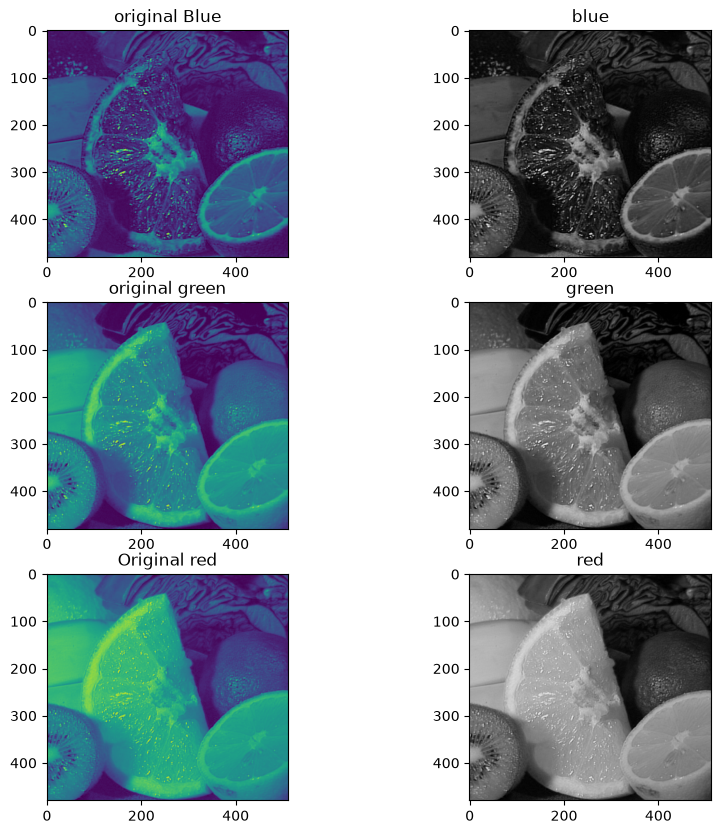

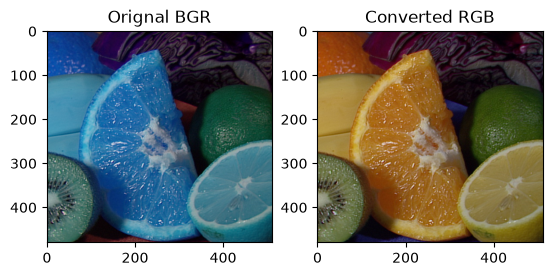

In [ ]:
# Importing the libraries
import cv2
import matplotlib.pyplot as plt


# Loading the fruits image
fruits_img = cv2.imread('..\\input\\fruits.jpg')


if fruits_img is None:
    raise ValueError("Error the image is not opening")


# 1. 
height,width,channels = fruits_img.shape
print("=="*30)
print(f"The Fruits image has :\nHeight: {height}\nWidth: {width}\nChannels: {channels}\nData Type: {fruits_img.dtype}")
pixel = fruits_img[50,50].copy()
print("The BGR ORDER:",pixel)
pixel[0],pixel[2] = pixel[2],pixel[0]
print("The RGB ORDER:",pixel)

# 2.Split the image into its blue, green and red channels and show all three as grayscale
# pictures next to the original

b,g,r = cv2.split(fruits_img)
fig,axes = plt.subplots(3,2,figsize=(10,10))
axes[0,0].imshow(b)
axes[0,0].set_title("original Blue")

axes[0,1].imshow(b,cmap='gray')
axes[0,1].set_title("blue")

axes[1,0].imshow(g)
axes[1,0].set_title("original green")

axes[1,1].imshow(g,cmap='gray')
axes[1,1].set_title("green")

axes[2,0].imshow(r)
axes[2,0].set_title("Original red")


axes[2,1].imshow(r,cmap='gray')
axes[2,1].set_title("red")



# 3.Show the original in the notebook with the correct colours.
print("=="*30)
print("Original Image")
fig,ax = plt.subplots(1,2)
ax[0].imshow(fruits_img)
ax[0].set_title("Orignal BGR")
ax[1].imshow(cv2.cvtColor(fruits_img,cv2.COLOR_BGR2RGB))
ax[1].set_title("Converted RGB")
cv2.waitKey(0)
cv2.destroyAllWindows()

# Question 2

In [529]:
def resize_And_watermark(img):
    """ 
        Function_name = resize_And_watermark
        parameters:
            img  = image source
        returns:
            None
        
        What function does:
            1. Resizes the original image with a fixed width and automatically adjusting the height shown below
            2. Croping a square from the image of size 200x200
            3. Adding a Text to one corner of the image
            results are shown  
    """
    
    
    fruits_img_c = img.copy()
    new_width = 300
    ratio = new_width/fruits_img_c.shape[1]

    # 1.
    fruits_img_c = cv2.resize(fruits_img_c,(0,0),fx =ratio ,fy=ratio)
    cv2.imshow("Fruits resized",fruits_img_c)
    print("Resized image shape:",fruits_img_c.shape)

    # 2.
    fruits_img_co = img.copy()
    h,w = fruits_img_co.shape[:2]
    center_cordinates = h//2,w//2
    
    cv2.imshow("original",fruits_img_co)
    crop = fruits_img_co[center_cordinates[0]:center_cordinates[0]+200,center_cordinates[1]:center_cordinates[1]+200]
    cv2.imshow("Center croped image",crop)
    print("Shape of Croped image:",crop.shape)
    
    # 3.
    cv2.putText(
        fruits_img_co,
        'SAMPLE',
        (10,30),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (254,100,200),
        1
    )
    cv2.imshow("SAMPLE IMAGE",fruits_img_co)
    os.makedirs('..\\output\\q_2',exist_ok=True)
    cv2.imwrite('..\\output\\q_2\\q_2_a.jpg',fruits_img_c)
    cv2.imwrite('..\\output\\q_2\\q_2_b.jpg',crop)
    cv2.imwrite('..\\output\\q_2\\q_2_c.jpg',fruits_img_co)
    cv2.waitKey(0)
    cv2.destroyAllWindows()


fruit_img = cv2.imread(r'..\fol\fruits.jpg')
resize_And_watermark(fruits_img)
cv2.destroyAllWindows()

Resized image shape: (281, 300, 3)
Shape of Croped image: (200, 200, 3)


# Question 3

In [115]:
import os 

def video_info(path):
    """
        Function_name : video_info
        Parameters:
            path: path of the video file 
        returns:
            dic : A dictionary containing the video Information
    """

    
    cap = cv2.VideoCapture(path)
    if not cap.isOpened(): raise IOError(path)
    dic = {
                'FPS': cap.get(cv2.CAP_PROP_FPS),
                'Frame Count' : cap.get(cv2.CAP_PROP_FRAME_COUNT),
                'Width' : cap.get(cv2.CAP_PROP_FRAME_WIDTH),
                'Height': cap.get(cv2.CAP_PROP_FRAME_HEIGHT),
                'Duration': cap.get(cv2.CAP_PROP_FRAME_COUNT)/cap.get(cv2.CAP_PROP_FPS)
        }
    return dic

            
info = video_info(r'..\input\vtest.avi')
print(info)


# 1.
cap = cv2.VideoCapture(r'..\input\vtest.avi')
cap.set(cv2.CAP_PROP_POS_MSEC, 10* 1000)
ret,frame = cap.read()
cv2.imshow("frame at 10s",frame)
if os.path.exists(r'..\output'):
    cv2.imwrite('..\\output\\q_3.png',frame)
else:
    os.mkdir(r"..\output")
    cv2.imwrite('..\\output\\q_3.png',frame)
print(f"Frame idx of 10s using the fps: {cap.get(cv2.CAP_PROP_FPS)*10}")
cv2.waitKey(0)
cv2.destroyAllWindows()

idx = int(cap.get(cv2.CAP_PROP_POS_FRAMES)) 
print("The index of next frame after 10s frame->",idx)


# 2.
cap = cv2.VideoCapture(r'..\input\vtest.avi')

if not cap.isOpened(): raise IOError('..\\input\\vtest.avi')
frame_count=0
try:
    print("Wait till the count is Finished.")
    while True:
        ret, frame = cap.read()
        if not ret: break
        frame_count+=1
        if cv2.waitKey(1) == ord('q'): break
finally:
    cap.release()
    cv2.destroyAllWindows()
print("Frame count by loop->",frame_count)


{'FPS': 10.0, 'Frame Count': 795.0, 'Width': 768.0, 'Height': 576.0, 'Duration': 79.5}
Frame idx of 10s using the fps: 100.0
The index of next frame after 10s frame-> 101
Wait till the count is Finished.
Frame count by loop-> 795


# Question 4

In [5]:
import numpy as np

candy= cv2.imread(r'..\input\smarties.png')

# Creating the copy of the image
c = candy.copy()


def mask_gen(hsv,color):
    """ 
        Function_name : mask_gen
        parameters:
            hsv: image in hsv format
            color : specified color for which mask is need
        returns:
            will return the mask of the respectice colors       
    """
    if color=='red':
        return cv2.inRange(hsv, (170, 120, 70), (179, 255, 255))
    elif color == 'orange':
        return cv2.inRange(hsv, (4, 140, 150), (26, 255, 255))
    elif color == 'green':
        return cv2.inRange(hsv,(35,80,150),(85,250,255))
    elif color == 'blue':
        return cv2.inRange(hsv, (85, 130, 150), (136, 255, 255))
    elif color =='brown':
        return cv2.inRange(hsv,(0, 100, 10), (10, 255, 90))
    else:
        raise ValueError("Color is not according to the set parameters")



def get_colour(color):
    """ 
        Function_name : get_colour
        parameters:
            color : specified color for which you want text colors to be displayed
        returns:
            will return a tuple of that respective color      
    """
    if color =='red':
        return (0,0,255)
    elif color == 'orange':
        return (25,140,200)
    elif color == 'green':
        return (0,255,0)
    elif color == 'blue':
        return (255,0,0)
    elif color == 'brown':
        return (2,60,100)
    else:
        raise ValueError("Color is not according to the set parameters")
    

def batch_check(dic):
    """ 
        Function_name : batch_check
        parameters:
            dic : takes a dictionary that has color and there cnt
        returns:
            Boolean (True/False)      
    """
    
    for key in dic.keys():
        if dic[key] > 4 or dic[key]<2:
            print(f"The Color : {key} has value : {dic[key]} not according to the standard")
            return False
        else:
            continue
    return True

    
#Defined color set of the CANDY QUALITY CONTROL 
colors = ['red','orange','green','blue','brown']

# HSV converted image
hsv = cv2.cvtColor(candy,cv2.COLOR_BGR2HSV)


# Creating an empty dictionary that will store the color and its count
cnts_col ={}

for i in range(len(colors)):
    # creating different masks for different colors
    masked = cv2.bitwise_and(hsv, hsv, mask=mask_gen(hsv,colors[i]))   
    # detecting the edges using canny
    edges = cv2.Canny(masked,100,255)
    
    # initializing the color count
    color_cnt=0
    contours,hier = cv2.findContours(edges,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    
    for cnt in contours:
        # Check the contour based on contour area
        if cv2.contourArea(cnt) >50:
            x, y, w, h = cv2.boundingRect(cnt)   
            cv2.rectangle(
                c,
                (x,y),
                (x+50,y+50),  # for correct bounding box len as acc to mask the size of cnt may be vary
                get_colour(colors[i]),
                2
            )
            
            color_cnt+=1
            cnts_col[colors[i]] = color_cnt
            
            cv2.putText(
                c,
                colors[i],
                (x+10,y-10),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                get_colour(colors[i])
            )

            
print("=="*20)
print("Counter per Color:")
for key,val in cnts_col.items():
    print(key,"-->", val)
print("=="*20)
print("Total Counts",sum(cnts_col.values()))
print("=="*20)
if batch_check(cnts_col):
    print("Success the Batch is passed!!!")
else:
    print("FAIL the batch is not good acc. to quality stds.!!")
    

cv2.imshow("Detected Colors",c)

cv2.imshow("Original",candy)
cv2.waitKey(0)
cv2.destroyAllWindows()

Counter per Color:
red --> 4
orange --> 2
green --> 2
blue --> 3
brown --> 1
Total Counts 12
The Color : brown has value : 1 not according to the standard
FAIL the batch is not good acc. to quality stds.!!


# Que 5

In [57]:
import cv2

img = cv2.imread(r"..\input\stuff.jpg")
img_c= img.copy()


gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), sigmaX=3, sigmaY=3)
mask = cv2.adaptiveThreshold(
    blur, 250, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV,21,5
)
kernel = np.ones((3, 3), np.uint8)
dilate = cv2.dilate(mask,kernel=kernel,iterations=3 )

# mask = cv2.morphologyEx(dilate, cv2.MORPH_OPEN, kernel,iterations=2)
# edges = cv2.Canny(mask,100,255)

cv2.imshow("mask", mask)
# cv2.imshow("Edges",edges)
contours, hier= cv2.findContours(
    dilate,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE
)
objects = []
obj_cnt = 0
sorted = sorted(contours, key= lambda contours:cv2.boundingRect(contours)[0])
for cnt in sorted:
    if cv2.contourArea(cnt)>700:
        obj_cnt+=1
        x,y,w,h = cv2.boundingRect(cnt)
        
        cv2.rectangle(img_c,(x,y),(x+w,y+h),(0,255,0),2)
        # cv2.drawContours(img_c,[cnt],0,(0,255,0),2)
        cv2.putText(img_c,str(obj_cnt),(x,y-10),cv2.FONT_HERSHEY_SIMPLEX,0.5,(0,255,0),2)
        objects.append(cnt)
        
cv2.imshow("desk",img_c)
cv2.waitKey(0)
cv2.destroyAllWindows()



In [32]:
cv2.destroyAllWindows()

# Que 6

In [530]:
planets = cv2.imread(r'..\input\planets.png')
pla_copied = planets.copy()
grayed_planet = cv2.cvtColor(planets,cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(grayed_planet,100,255)

contours,hier = cv2.findContours(edges,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

area_of_planets =[]
maxx=0
sc_maxx=maxx
for cnt in contours:
    area = cv2.contourArea(cnt)
    area_of_planets.append(area)
    if area>maxx:
        sc_maxx = maxx
        maxx = area
    elif area>sc_maxx and area<maxx:
        sc_maxx = area
        

for cnt in contours:
    if cv2.contourArea(cnt) == sc_maxx:
        x,y,w,h = cv2.boundingRect(cnt)
        cv2.rectangle(
            pla_copied,
            (x,y),
            (x+w,y+h),
            (255,255,255),
            2
        )
        cv2.putText(
            pla_copied,
            "Biggest Planet",
            (x+20,y-20),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (255,255,255),
            1
        )
cv2.imshow("Biggest planet",pla_copied)
cv2.imwrite('..\\output\\q_6.jpg',pla_copied)
print("=="*20)
print("Total No. of Objects :",len(area_of_planets))
print("The size of Biggest planet in pixels:",sc_maxx)
# cv2.imshow("Planets",planets)
cv2.waitKey(0)
cv2.destroyAllWindows()

Total No. of Objects : 9
The size of Biggest planet in pixels: 11842.0


# Que 7

In [85]:
import time

cap = cv2.VideoCapture(0)
fps    = cap.get(cv2.CAP_PROP_FPS) or 30  
W, H   = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
out = cv2.VideoWriter('..\\output\\q_7.mp4',cv2.VideoWriter_fourcc(*"mp4v"),fps,(W,H))
if not cap.isOpened():
    raise ValueError("Camera is not opened")

# 1. loaded the haarcascade 
cas = cv2.CascadeClassifier( r"..\input\haarcascade_frontalface_default.xml")
if cas.empty(): raise IOError("cascade not loaded")
frame_count = 0
f_frame_cnt=0
w_frame_count=0
t0 = time.perf_counter()
cap_= True
start,end = 0,0
while True:
    ret,frame = cap.read()
    if not ret: break
    frame_count += 1
    w_frame_count+=1
    # converted the frame to grayscale
    grayed = cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY)
    boxes= cas.detectMultiScale(grayed, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60), maxSize=(0, 0))

    loc = (0,0,0,0)

    maxx = 0
    for x,y,w,h in boxes:
        
        if w*h>maxx:
            maxx = w*h
            loc = x,y,w,h
            
            
    if len(boxes):
        w_frame_count = 0
        if not cap_:
            end = time.perf_counter()-t0
            cap_ = True
            print(f"Warning : {start},{end}")
        f_frame_cnt+=1    
        cv2.rectangle(
            frame,
            (loc[0],loc[1]),
            (loc[0]+loc[2],loc[1]+loc[3]),
            (0,255,0),
            2
        )
        
        cv2.putText(frame,
                    "Face ok",
                    (loc[0]-10,loc[1]-10),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    1,
                    (0,255,0),
                    1)   
        
    else:
        cv2.putText(frame,
                    "Face not found",
                    (10,30),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    1,
                    (0,0,255),
                    1)
        if w_frame_count>=33:
            if cap_:
                start = time.perf_counter()-t0
                cap_ = False
            
            cv2.putText(frame,
                "WARNING",
                (400,30),
                cv2.FONT_HERSHEY_SIMPLEX,
                1,
                (0,0,255),
                1)
    cv2.imshow("frame",frame)
    out.write(frame)
    
    if cv2.waitKey(1)==ord('q'):
        break
cap.release()
out.release()
cv2.destroyAllWindows()
print("Total percentage of frames captured : ",f_frame_cnt/frame_count*100)



Total percentage of frames captured :  44.04332129963899


# Que 8

In [17]:
import cv2
import numpy as np
cap = cv2.VideoCapture(r'..\input\fruit-and-vegetable-detection.mp4')
if not cap.isOpened():
    raise ValueError("Camera is not opened")

def classify_fruit(hsv_roi, mask):
    """Simple and corrected color classification."""
    h = hsv_roi[:, :, 0][mask > 0]
    s = hsv_roi[:, :, 1][mask > 0]
    v = hsv_roi[:, :, 2][mask > 0]
    
    if len(h) == 0:
        return "unknown", (255, 255, 255)

    h_med, s_med, v_med = np.median(h), np.median(s), np.median(v)
    
    if s_med < 40 or v_med < 40:
        return "dark", (128, 128, 128)
    
    # Corrected HSV ranges for OpenCV (0-180)
    if h_med < 10 or h_med > 170:
        return "red", (0, 0, 255)
    elif h_med < 22:
        return "orange", (0, 165, 255)
    elif h_med < 35:  # Fixed: was logically impossible before
        return "yellow", (0, 255, 255)
    elif h_med < 90:
        return "green", (0, 255, 0)
    else:
        return "blue", (255, 0, 0)

bg = cv2.createBackgroundSubtractorMOG2(history=300, varThreshold=16, detectShadows=False)

item_cnt=0
cpresent=False


frame_idx = 0   
while True:
    ret, frame_o = cap.read()
    
    if not ret:
        break
    frame_idx += 1
    frame = frame_o.copy()
    top_strip = frame[0:400,0:300]
    hsv_roi = cv2.cvtColor(top_strip, cv2.COLOR_BGR2HSV)
    fg = bg.apply(top_strip)
    _,mask = cv2.threshold(fg,200,255,cv2.THRESH_BINARY)
    fg = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5,5),np.uint8))
    # fg = cv2.morphologyEx(fg, cv2.MORPH_CLOSE, np.ones((5,5),np.uint8))
    contours,hier = cv2.findContours(fg,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    cnt_max = [cnt for cnt in contours if cv2.contourArea(cnt)>1800]

    if cnt_max:
        if not cpresent:
            item_cnt+=1
            cpresent=True
            
        for cnt in contours:
            x,y,w,h = cv2.boundingRect(cnt)
            color_name, color_bgr = classify_fruit(hsv_roi, mask)
            cv2.rectangle(
                frame,
                (x,y),
                (x+w,y+h),
                color_bgr,
                1
            )
            cv2.putText(
                frame,
                color_name,
                (x,y-10),
                cv2.FONT_HERSHEY_SIMPLEX,
                1,
                color_bgr,
                2
            )
            
    else:
        cpresent=False
    cv2.putText(
        frame,
        f"Count: {item_cnt}",
        (10,30),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (255,255,255),
        1
    )
    cv2.imshow("croped",fg)
    cv2.imshow('frame',frame)
    if cv2.waitKey(1)==ord('q'): break
cap.release()
cv2.destroyAllWindows()

print("Total item cnt",item_cnt)

Total item cnt 26


# Que 9

In [25]:
import numpy as np
corrs = []
def mouse_event(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN: 
        print((x,y))
        corrs.append([x, y])      # also RBUTTONDOWN, MOUSEMOVE

def get_cors():
    cap = cv2.VideoCapture(r'..\input\worker-zone-detection.mp4')
    ret,frame = cap.read()
    cv2.imshow("selectROI",cv2.resize(frame,(0,0),fx=0.5,fy=0.5))
    cv2.setMouseCallback("selectROI", mouse_event)
    cv2.waitKey(0)
    cv2.destroyWindow("selectROI")
    return corrs

zones = np.array(get_cors())

# Loading the model part
model_path = '..\input\yolov8n.onnx'
video_path = '..\input\worker-zone-detection.mp4'

net = cv2.dnn.readNet(model_path)

if net.empty():
    raise RuntimeWarning("Could not load the network!")

cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise RuntimeWarning("Could not open the video file!")

class_names = ["person","bicycle","car","motorcycle","airplane","bus","train","truck","boat","traffic light",
        "fire hydrant","stop sign","parking meter","bench","bird","cat","dog","horse","sheep","cow",
        "elephant","bear","zebra","giraffe","backpack","umbrella","handbag","tie","suitcase","frisbee",
        "skis","snowboard","sports ball","kite","baseball bat","baseball glove","skateboard","surfboard",
        "tennis racket","bottle","wine glass","cup","fork","knife","spoon","bowl","banana","apple",
        "sandwich","orange","broccoli","carrot","hot dog","pizza","donut","cake","chair","couch",
        "potted plant","bed","dining table","toilet","tv","laptop","mouse","remote","keyboard",
        "cell phone","microwave","oven","toaster","sink","refrigerator","book","clock","vase",
        "scissors","teddy bear","hair drier","toothbrush"]

conf_th = 0.5
nms_th = 0.45
input_size = 640

while True:
    ret,frame = cap.read()
    if not ret:
        break
    orig_h,orig_w = frame.shape[:2]
    blob = cv2.dnn.blobFromImage(frame, 1/255.0, (640, 640), swapRB=True, crop=False)

    # RUN THE YOLO inference
    net.setInput(blob)
    outputs = net.forward()
    
    #yolo outputs shape [1, 84, 8400]
    #transpose to [8400, 84]
    predictions = outputs[0].T
    
    boxes = []
    confidences = []
    class_ids = []
    
    # decode the filter prediction
    for prediction in predictions:
        # get the 80 class Scores
        class_scores = prediction[4:]
        
        class_id = int(np.argmax(class_scores))
        confidence = float(class_scores[class_id])
        
        if confidence < conf_th:
            continue
        
        if not 0<=class_id < len(class_names):
            continue
        
        # get the bounding box
        cx,cy,w,h = prediction[:4]
        
        # convert center cordinates to corners
        x1 = cx - w/2
        y1 = cy - h/2
        x2 = cx + w/2
        y2 = cy + h/2
        
        # Scale to the original image
        x1 *= orig_w / input_size
        x2 *= orig_w / input_size
        y1 *= orig_h / input_size
        y2 *= orig_h / input_size

        # Clamp coordinates to the image boundaries
        x1 = max(0,min(int(x1),orig_w-1))
        y1 = max(0,min(int(y1),orig_h-1))
        x2 = max(0,min(int(x2),orig_w-1))
        y2 = max(0,min(int(y2),orig_h-1))
        
        boxes.append([x1,y1,x2,y2])
        confidences.append(confidence)
        class_ids.append(class_id)
        
    # Applying the nms
    indices = cv2.dnn.NMSBoxes(
        boxes, confidences, conf_th, nms_th
    )
    
    if len(indices)>0:
        indices = np.array(indices).flatten().tolist()
    else:
        indices = []
        
    # draw final detections
    out_frame = frame.copy()
    
    for i in indices:
        x,y,w,h = boxes[i]
        confidence = confidences[i]
        class_id = class_ids[i]
        
        label_name = class_names[class_id]
        label = f"{label_name} {confidence*100:.2f}%"
        
        cv2.rectangle(out_frame, (x,y), (x+w,y+h), (0,255,0), 2)
        
        # calculate label dimensions
        (text_w,text_h),baseline = cv2.getTextSize(
            label,
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            2
        )
        
        label_y = max(y,text_h+baseline)
        
        # filled label backgrounf
        cv2.rectangle(
            out_frame,
            (x,label_y-text_h-baseline),
            (x+text_w,label_y),
            (0,255,0),
            -1
        )
        
        # draw label
        cv2.putText(
            out_frame,
            label,
            (x,label_y-text_h-baseline),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0,255,0),
            2
        )
    cv2.putText(out_frame, f"{len(indices)} detections", (10, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)    
    cv2.imshow('frame',out_frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break
cap.release()
cv2.destroyAllWindows()
    
print(zones)
# cv2.destroyWindow('selectROI')

<>:20: SyntaxWarning: invalid escape sequence '\i'
<>:21: SyntaxWarning: invalid escape sequence '\i'
<>:20: SyntaxWarning: invalid escape sequence '\i'
<>:21: SyntaxWarning: invalid escape sequence '\i'
C:\Users\Hemang.bodana\AppData\Local\Temp\ipykernel_23824\1228580418.py:20: SyntaxWarning: invalid escape sequence '\i'
  model_path = '..\input\yolov8n.onnx'
C:\Users\Hemang.bodana\AppData\Local\Temp\ipykernel_23824\1228580418.py:21: SyntaxWarning: invalid escape sequence '\i'
  video_path = '..\input\worker-zone-detection.mp4'


(14, 3)
(518, 1)
(512, 264)
(214, 536)
[[ 14   3]
 [518   1]
 [512 264]
 [214 536]]


In [28]:
import os
import csv
import cv2
import numpy as np

# --------------------------------------------------
# 1. SETTINGS
# --------------------------------------------------
video_path = r"..\input\worker-zone-detection.mp4"
model_path = r"..\input\yolov8n.onnx"

output_video = "worker_zone_output.mp4"
output_csv = "alerts.csv"

CONF_TH = 0.50
NMS_TH = 0.45
INPUT_SIZE = 640

# Performance settings
RESIZE_SCALE = 0.5       # 1920x1080 -> 960x540
FRAME_SKIP = 2           # Run YOLO every 2 frames (about 30 FPS)
N_CONSECUTIVE = 5        # Require 5 consecutive positive inferences

# --------------------------------------------------
# 2. OPEN VIDEO AND SELECT DANGER ZONE
# --------------------------------------------------
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise RuntimeError(f"Cannot open video: {video_path}")

fps = cap.get(cv2.CAP_PROP_FPS)
if not fps or fps <= 0:
    fps = 60.0

orig_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
orig_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

ret, first_frame = cap.read()
if not ret:
    cap.release()
    raise RuntimeError("Cannot read the first frame.")

# The polygon is selected on a half-size preview.
preview = cv2.resize(
    first_frame, None,
    fx=RESIZE_SCALE, fy=RESIZE_SCALE
)

selected_points = []
display = preview.copy()


def mouse_event(event, x, y, flags, param):
    global display

    if event == cv2.EVENT_LBUTTONDOWN:
        selected_points.append((x, y))
        cv2.circle(display, (x, y), 5, (0, 255, 255), -1)

        if len(selected_points) > 1:
            cv2.line(
                display,
                selected_points[-2],
                selected_points[-1],
                (0, 255, 255), 2
            )

        cv2.imshow("Select danger zone", display)


cv2.namedWindow("Select danger zone")
cv2.setMouseCallback("Select danger zone", mouse_event)

print("Click at least 3 corners around the marked floor danger zone.")
print("Click corners in order around its boundary, then press ENTER.")
print("Press R to reset the selected points.")


# SELECT DANGER ZONE POLYGON OR RESET
while True:
    cv2.imshow("Select danger zone", display)
    key = cv2.waitKey(20) & 0xFF

    if key == 13:  # Enter
        if len(selected_points) >= 3:
            break
        print("Please select at least 3 points.")

    elif key == ord("r"):
        selected_points.clear()
        display = preview.copy()

    elif key == 27:  # Escape
        cap.release()
        cv2.destroyAllWindows()
        raise RuntimeError("Zone selection cancelled.")

cv2.destroyWindow("Select danger zone")

# Convert preview coordinates to original-video coordinates.
zones = np.array(
    [
        (round(x / RESIZE_SCALE), round(y / RESIZE_SCALE))
        for x, y in selected_points
    ],
    dtype=np.int32
)

print("Danger zone polygon:", zones.tolist())

# --------------------------------------------------
# 3. LOAD YOLO ONNX MODEL
# --------------------------------------------------
if not os.path.isfile(model_path):
    cap.release()
    raise FileNotFoundError(f"Model file not found: {model_path}")

net = cv2.dnn.readNetFromONNX(model_path)

# --------------------------------------------------
# 4. SET UP OUTPUT VIDEO (Video Writer)
# --------------------------------------------------
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(
    output_video, fourcc, fps, (orig_w, orig_h)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Cannot create output video.")

# Rewind after reading the first frame for zone selection.
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

# --------------------------------------------------
# 5. ALERT STATE
# --------------------------------------------------
frame_idx = 0
inside_streak = 0

alert_active = False
streak_start_time = None
alert_start_time = None
last_inside_time = None

alerts = []

# Keep the latest detections between YOLO inference frames.
last_detections = []

# --------------------------------------------------
# 6. PROCESS VIDEO
# --------------------------------------------------
while True:
    ret, frame = cap.read()
    if not ret:
        break

    timestamp = frame_idx / fps

    # Run inference only on every FRAME_SKIP-th frame.
    if frame_idx % FRAME_SKIP == 0:

        # Resize for faster processing.
        small = cv2.resize(
            frame, None,
            fx=RESIZE_SCALE, fy=RESIZE_SCALE
        )
        small_h, small_w = small.shape[:2]

        blob = cv2.dnn.blobFromImage(
            small,
            scalefactor=1.0 / 255.0,
            size=(INPUT_SIZE, INPUT_SIZE),
            swapRB=True,
            crop=False
        )

        net.setInput(blob)
        outputs = net.forward()

        # YOLOv8 output is usually [1, 84, 8400].
        predictions = outputs[0]

        if predictions.shape[0] == 84:
            predictions = predictions.T
        elif predictions.shape[1] == 84:
            pass
        else:
            cap.release()
            writer.release()
            raise RuntimeError(
                f"Unexpected YOLO output shape: {outputs.shape}"
            )

        boxes = []
        confidences = []
        feet_points = []

        scale_x = small_w / INPUT_SIZE
        scale_y = small_h / INPUT_SIZE

        # Decode person detections only (class ID 0).
        for pred in predictions:
            class_scores = pred[4:]
            class_id = int(np.argmax(class_scores))
            confidence = float(class_scores[class_id])

            if class_id != 0 or confidence < CONF_TH:
                continue

            cx, cy, w, h = pred[:4]

            # Model coordinates -> resized-frame coordinates.
            x1 = int((cx - w / 2) * scale_x)
            y1 = int((cy - h / 2) * scale_y)
            x2 = int((cx + w / 2) * scale_x)
            y2 = int((cy + h / 2) * scale_y)

            # Resized-frame coordinates -> original coordinates.
            x1 = int(x1 / RESIZE_SCALE)
            y1 = int(y1 / RESIZE_SCALE)
            x2 = int(x2 / RESIZE_SCALE)
            y2 = int(y2 / RESIZE_SCALE)

            x1 = max(0, min(x1, orig_w - 1))
            y1 = max(0, min(y1, orig_h - 1))
            x2 = max(0, min(x2, orig_w - 1))
            y2 = max(0, min(y2, orig_h - 1))

            if x2 <= x1 or y2 <= y1:
                continue

            # OpenCV NMSBoxes expects (x, y, width, height).
            boxes.append([x1, y1, x2 - x1, y2 - y1])
            confidences.append(confidence)

        # Suppress duplicate person detections.
        indices = cv2.dnn.NMSBoxes(
            boxes, confidences, CONF_TH, NMS_TH
        )

        if len(indices) > 0:
            indices = np.array(indices).flatten()
        else:
            indices = []

        last_detections = []
        person_inside = False

        for i in indices:
            x, y, w, h = boxes[int(i)]

            # Bottom-middle of bounding box = feet position.
            foot_x = x + w // 2
            foot_y = y + h

            is_inside = cv2.pointPolygonTest(
                zones,
                (float(foot_x), float(foot_y)),
                False
            ) >= 0

            if is_inside:
                person_inside = True

            last_detections.append(
                (x, y, w, h, confidences[int(i)],
                 foot_x, foot_y, is_inside)
            )

        # Update the consecutive-positive counter.
        if person_inside:
            if inside_streak == 0:
                streak_start_time = timestamp

            inside_streak += 1
            last_inside_time = timestamp

            if inside_streak >= N_CONSECUTIVE and not alert_active:
                alert_active = True
                alert_start_time = streak_start_time

                print(
                    f"ALERT START: {alert_start_time:.2f} seconds"
                )

        else:
            inside_streak = 0
            streak_start_time = None

            if alert_active:
                alerts.append(
                    (alert_start_time, last_inside_time)
                )

                print(
                    f"ALERT END: {last_inside_time:.2f} seconds"
                )

                alert_active = False
                alert_start_time = None
                last_inside_time = None

    # --------------------------------------------------
    # 7. DRAW ZONE AND PERSON DETECTIONS
    # --------------------------------------------------
    out_frame = frame.copy()

    zone_color = (0, 0, 255) if alert_active else (0, 255, 0)

    cv2.polylines(
        out_frame, [zones], True, zone_color, 3
    )

    # Light transparent zone fill.
    overlay = out_frame.copy()
    cv2.fillPoly(overlay, [zones], zone_color)
    out_frame = cv2.addWeighted(
        overlay, 0.15, out_frame, 0.85, 0
    )

    # Redraw the polygon outline over the fill.
    cv2.polylines(
        out_frame, [zones], True, zone_color, 3
    )

    for (x, y, w, h, conf, fx, fy, is_inside) in last_detections:
        color = (0, 0, 255) if is_inside else (255, 200, 0)

        cv2.rectangle(
            out_frame, (x, y), (x + w, y + h), color, 2
        )
        cv2.circle(out_frame, (fx, fy), 5, color, -1)

        cv2.putText(
            out_frame,
            f"person {conf:.2f}",
            (x, max(20, y - 8)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6, color, 2
        )

    status = "ALERT: DANGER ZONE" if alert_active else "Zone clear"
    status_color = (0, 0, 255) if alert_active else (0, 255, 0)

    cv2.putText(
        out_frame, status, (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX, 1.0, status_color, 2
    )

    cv2.putText(
        out_frame,
        f"Inside streak: {inside_streak}/{N_CONSECUTIVE}",
        (20, 80),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7, (255, 255, 255), 2
    )

    # Save every frame, even when inference is skipped.
    writer.write(out_frame)

    cv2.imshow("Worker danger zone", out_frame)

    if cv2.waitKey(50) & 0xFF == ord("q"):
        break

    frame_idx += 1

# --------------------------------------------------
# 8. CLOSE ANY ALERT STILL ACTIVE AT VIDEO END
# --------------------------------------------------
if alert_active:
    alerts.append((alert_start_time, last_inside_time))
    print(f"ALERT END: {last_inside_time:.2f} seconds (video ended)")

cap.release()
writer.release()
cv2.destroyAllWindows()

# --------------------------------------------------
# 9. SAVE ALERT TIMES TO CSV
# --------------------------------------------------
with open(output_csv, "w", newline="") as f:
    csv_writer = csv.writer(f)
    csv_writer.writerow(["start_time_seconds", "end_time_seconds"])

    for start, end in alerts:
        csv_writer.writerow([
            f"{start:.2f}",
            f"{end:.2f}"
        ])

print(f"Saved video: {output_video}")
print(f"Saved alert log: {output_csv}")
print(f"Total alerts: {len(alerts)}")


Click at least 3 corners around the marked floor danger zone.
Click corners in order around its boundary, then press ENTER.
Press R to reset the selected points.
Danger zone polygon: [[36, 32], [1024, 24], [1022, 510], [450, 1070], [38, 40]]
ALERT START: 15.22 seconds
ALERT END: 25.66 seconds
ALERT START: 25.73 seconds
ALERT END: 26.73 seconds
ALERT START: 37.47 seconds
ALERT END: 37.64 seconds
ALERT START: 37.70 seconds
ALERT END: 38.17 seconds
ALERT START: 38.44 seconds
ALERT END: 39.97 seconds
ALERT START: 51.92 seconds
ALERT END: 52.32 seconds
Saved video: worker_zone_output.mp4
Saved alert log: alerts.csv
Total alerts: 6


In [24]:
cv2.destroyAllWindows()

# Que 10
`Solution`
1.
Steps:
1. Will get those frame and resize it 
2. After that we will convert the bgr to gray scale
3. Select ROI 
4. Use the ROI and Apply medianblur to remove small irrelavant noise of sunlights,mist,etc
5. Apply Adaptive Thresholding onto it 

2.
Detections:

From the selected ROI will apply background subtractor onto that after that will try to get contours of that so that if an Vechile is there so definitely its area will be greater than that of pedistrian or cyclist. 

3.
Post Processing
we can merge multiple frames that are kind of similar
we can remove the frames that are not in use means where the actutal detection is not ever going to take place as there is no vehicle 
we can track vechile by the motion diff of it that how there is the change in the image 
we can initialize a counter for each vehicle we can let tht cnt to update else none
 when the counter is updated the time should start calculating and if the time execeeds that the limit that is 30 sec we can play the alert sound by noticing there is not such significant change in the windows of the ROI

4.
Failure
System gets failed if at night the vehicle moves in or out then the light can cause errors in the background if two vechiles in opposite direction is at the roi at night and light of both vehicle is on then the detection might fail as well

5.
performance
the system can use various frame skipping like skipping a fixed amount of frame and after that the detection to take place or one can use the jumping thing like jump at this frame over there detection is processed one can let the detection's histry like small window that when there is the change the detection should then start and with a neccessay buffer size the detection should take according to that
